# GTEx V11: cross-region transcriptomic prediction
**BMEN 600 | Colab analysis notebook**

**Research question:** How accurately can gene expression in one human brain region predict expression in another region in unseen donors, and how does prediction performance vary across region pairs?

This notebook uses your 13 uploaded GTEx V11 **gene-read-count** files. It starts with caudate → putamen; an optional switch runs every eligible ordered pair. The spinal cord is a separate nervous-system region, not a brain region, and is excluded from the main analysis by default.

**How to run:** Open [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**, upload this `.ipynb`, then execute cells in order. Upload the `.gct.gz` files in section 2, or put them in a Google Drive folder. A CPU runtime is sufficient. All-pair analysis takes substantially longer than the example. Results are generated from data when run; no findings are prewritten.

**Verified example run:** Caudate → putamen, 233 paired donors (186 development, 47 test). Ridge prediction skill = 0.501; conditional donor-bootstrap 95% interval = 0.302–0.663. These are exploratory results for 200 training-selected target genes and one donor split. The four saved graph outputs below come from this run. Rerunning replaces them with your current analysis. Colab upload/mount/download cells require Colab; the loading, modelling and graph cells were tested locally on the supplied files.


## 1. Scientific rationale and analysis choices
Regional gene-expression patterns have been mapped in the Allen Human Brain Atlas [1], and reproducible transcriptional signatures have been related to anatomical and cellular organization [2]. GTEx provides a multi-tissue bulk RNA-seq resource [3]. These studies motivate the question; they do not establish that this notebook's prediction model will succeed.

Each independent case is a **donor**, not a gene or a tissue sample. Source and target regions must come from the same donor. A held-out donor's target measurements never enter fitting, feature selection, scaling, or tuning. Ridge regression provides regularization for correlated, high-dimensional predictors [5]; a separate inner validation split selects its penalty without using the test set [6].

We use log2(CPM + 1), calculated per sample from the complete count matrix. This is an exploratory normalization, **not TPM** and not TMM. Library-size scaling may retain compositional bias [4]; compare against TMM or another justified normalization before strong conclusions. These files alone lack age, sex, RIN, postmortem interval and batch metadata. Apparent transferability can reflect these factors or cell-type composition [3]. This analysis cannot establish neurodegenerative mechanisms, disease biomarkers or clinical utility.

In [ ]:
from pathlib import Path
import gzip, json, hashlib, platform, itertools, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
RUN_ALL_PAIRS = False
INCLUDE_SPINAL_CORD = False
SOURCE = 'caudate_basal_ganglia'
TARGET = 'putamen_basal_ganglia'
MIN_PAIRED_DONORS = 60
N_SOURCE_GENES = 500
N_TARGET_GENES = 200
ALPHAS = [1., 10., 100., 1000.]
N_BOOTSTRAPS = 1000
OUT = Path('/content/gtex_results')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 2. Supply the count files
Use `upload` to select all your `.gct.gz` files (about 184 MB total), or `drive` to mount Drive. The files are not embedded in this notebook. Do not upload the project PDF here.

In [ ]:
INPUT_MODE = 'upload'  # change to 'drive' for persistent input files
DRIVE_FOLDER = '/content/drive/MyDrive/GTEx_V11_brain'
if INPUT_MODE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path(DRIVE_FOLDER)
else:
    from google.colab import files
    DATA_DIR = Path('/content/gtex_input')
    DATA_DIR.mkdir(exist_ok=True)
    uploaded = files.upload()
    for name, data in uploaded.items():
        (DATA_DIR / Path(name).name).write_bytes(data)
    del uploaded
paths = sorted(DATA_DIR.glob('gene_reads_adult_gtex_v11_brain_*.gct.gz'))
assert len(paths) >= 2, 'At least two region files are needed. Check your folder and filenames.'
print('Region files found:', len(paths))

## 3. Load, validate and normalize
A GCT 1.2 file has a version line, a dimensions line, then the table. `Name` identifies genes and `Description` supplies symbols. GTEx donor IDs are the first two hyphen-separated fields of the sample ID. Multiple samples for one donor within a region are averaged **after sample-level normalization**; the summary records this choice. We retain full Ensembl IDs to avoid collisions.

In [ ]:
def load_region(path):
    with gzip.open(path, 'rt') as f:
        version = f.readline().strip()
        n_genes, n_samples = map(int, f.readline().split())
    if version != '#1.2':
        raise ValueError(f'Unsupported GCT version: {version}')
    table = pd.read_csv(path, sep='\t', skiprows=2)
    if table.shape != (n_genes, n_samples + 2):
        raise ValueError(f'Dimension mismatch: {path.name}')
    if table['Name'].duplicated().any():
        raise ValueError('Duplicate gene IDs')
    symbols = table.set_index('Name')['Description']
    counts = table.iloc[:, 2:].astype('float32')
    counts.index = table['Name']
    if not np.isfinite(counts.to_numpy()).all() or (counts.to_numpy() < 0).any():
        raise ValueError('Counts must be finite and nonnegative')
    libraries = counts.sum(axis=0)
    if (libraries <= 0).any():
        raise ValueError('Zero-count sample found')
    donors = []
    for sample in counts.columns:
        parts = sample.split('-')
        if len(parts) < 3 or parts[0] != 'GTEX':
            raise ValueError(f'Unexpected sample ID: {sample}')
        donors.append('-'.join(parts[:2]))
    logcpm = np.log2(counts.div(libraries, axis=1) * 1e6 + 1).T
    logcpm.index = donors
    matrix = logcpm.groupby(level=0, sort=True).mean().astype('float32')
    record = dict(region=path.name.removeprefix('gene_reads_adult_gtex_v11_brain_').removesuffix('.gct.gz'),
                  genes=n_genes, samples=n_samples, donors=len(matrix),
                  extra_samples=n_samples-len(matrix), median_library_reads=float(libraries.median()),
                  sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    return matrix, symbols, record

regions, symbols, records = {}, {}, []
for path in paths:
    matrix, gene_symbols, record = load_region(path)
    regions[record['region']] = matrix
    symbols[record['region']] = gene_symbols
    records.append(record)
    print(record['region'], matrix.shape)
summary = pd.DataFrame(records)
summary.to_csv(OUT / 'table_1_dataset_summary.csv', index=False)
display(summary.drop(columns='sha256'))
active = sorted(r for r in regions if INCLUDE_SPINAL_CORD or not r.startswith('spinal_cord'))
overlap = pd.DataFrame([[len(regions[a].index.intersection(regions[b].index)) for b in active] for a in active], index=active, columns=active)
overlap.to_csv(OUT / 'donor_overlap.csv')

## 4. Dataset graphs
**Figure 1.** Unique donors per uploaded region after within-region aggregation. Counts describe available data, not the number used in every pair.

**Figure 2.** Donors with measurements in both regions. Each pair can have a different cohort. This limits direct comparison between pair scores.

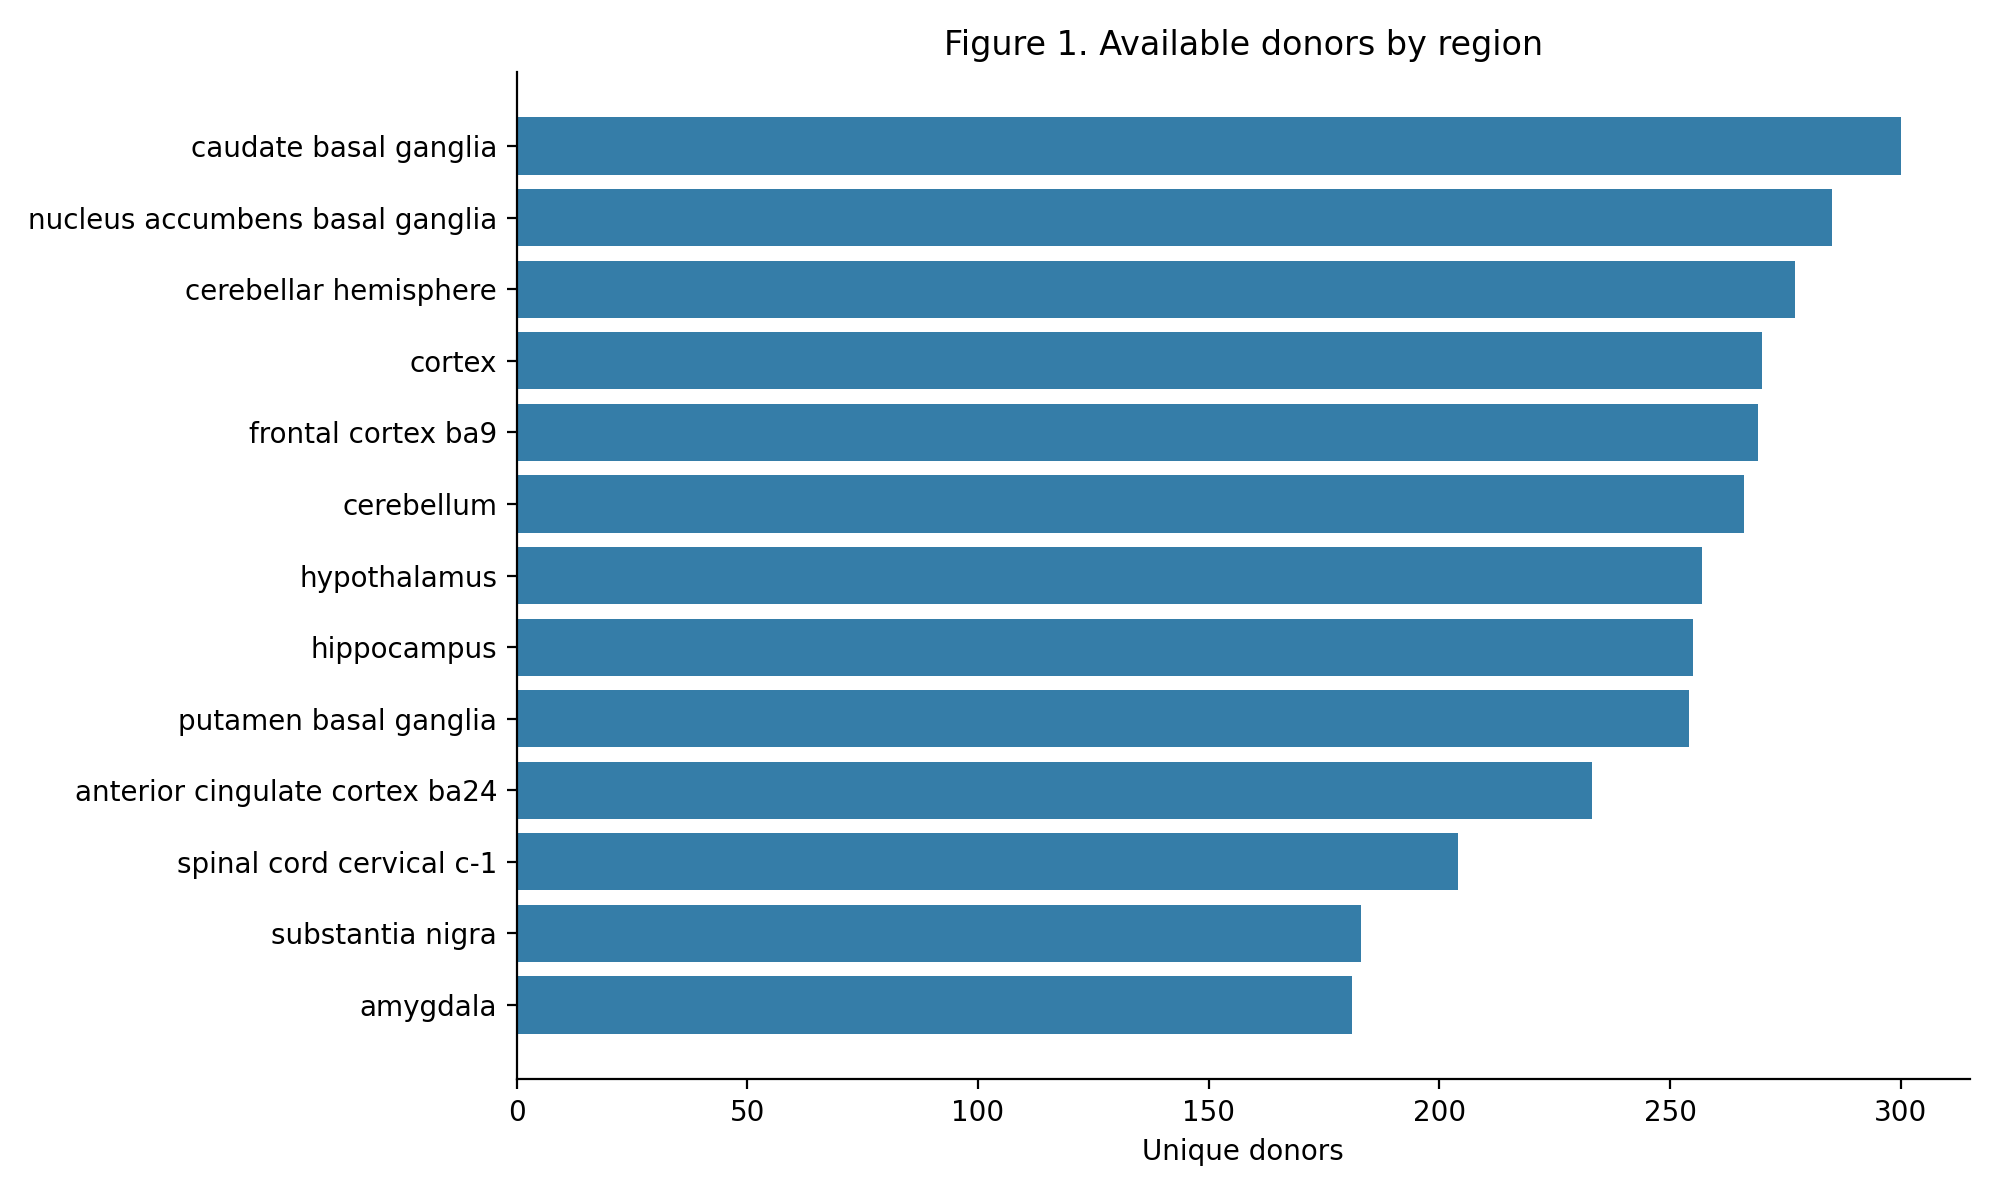

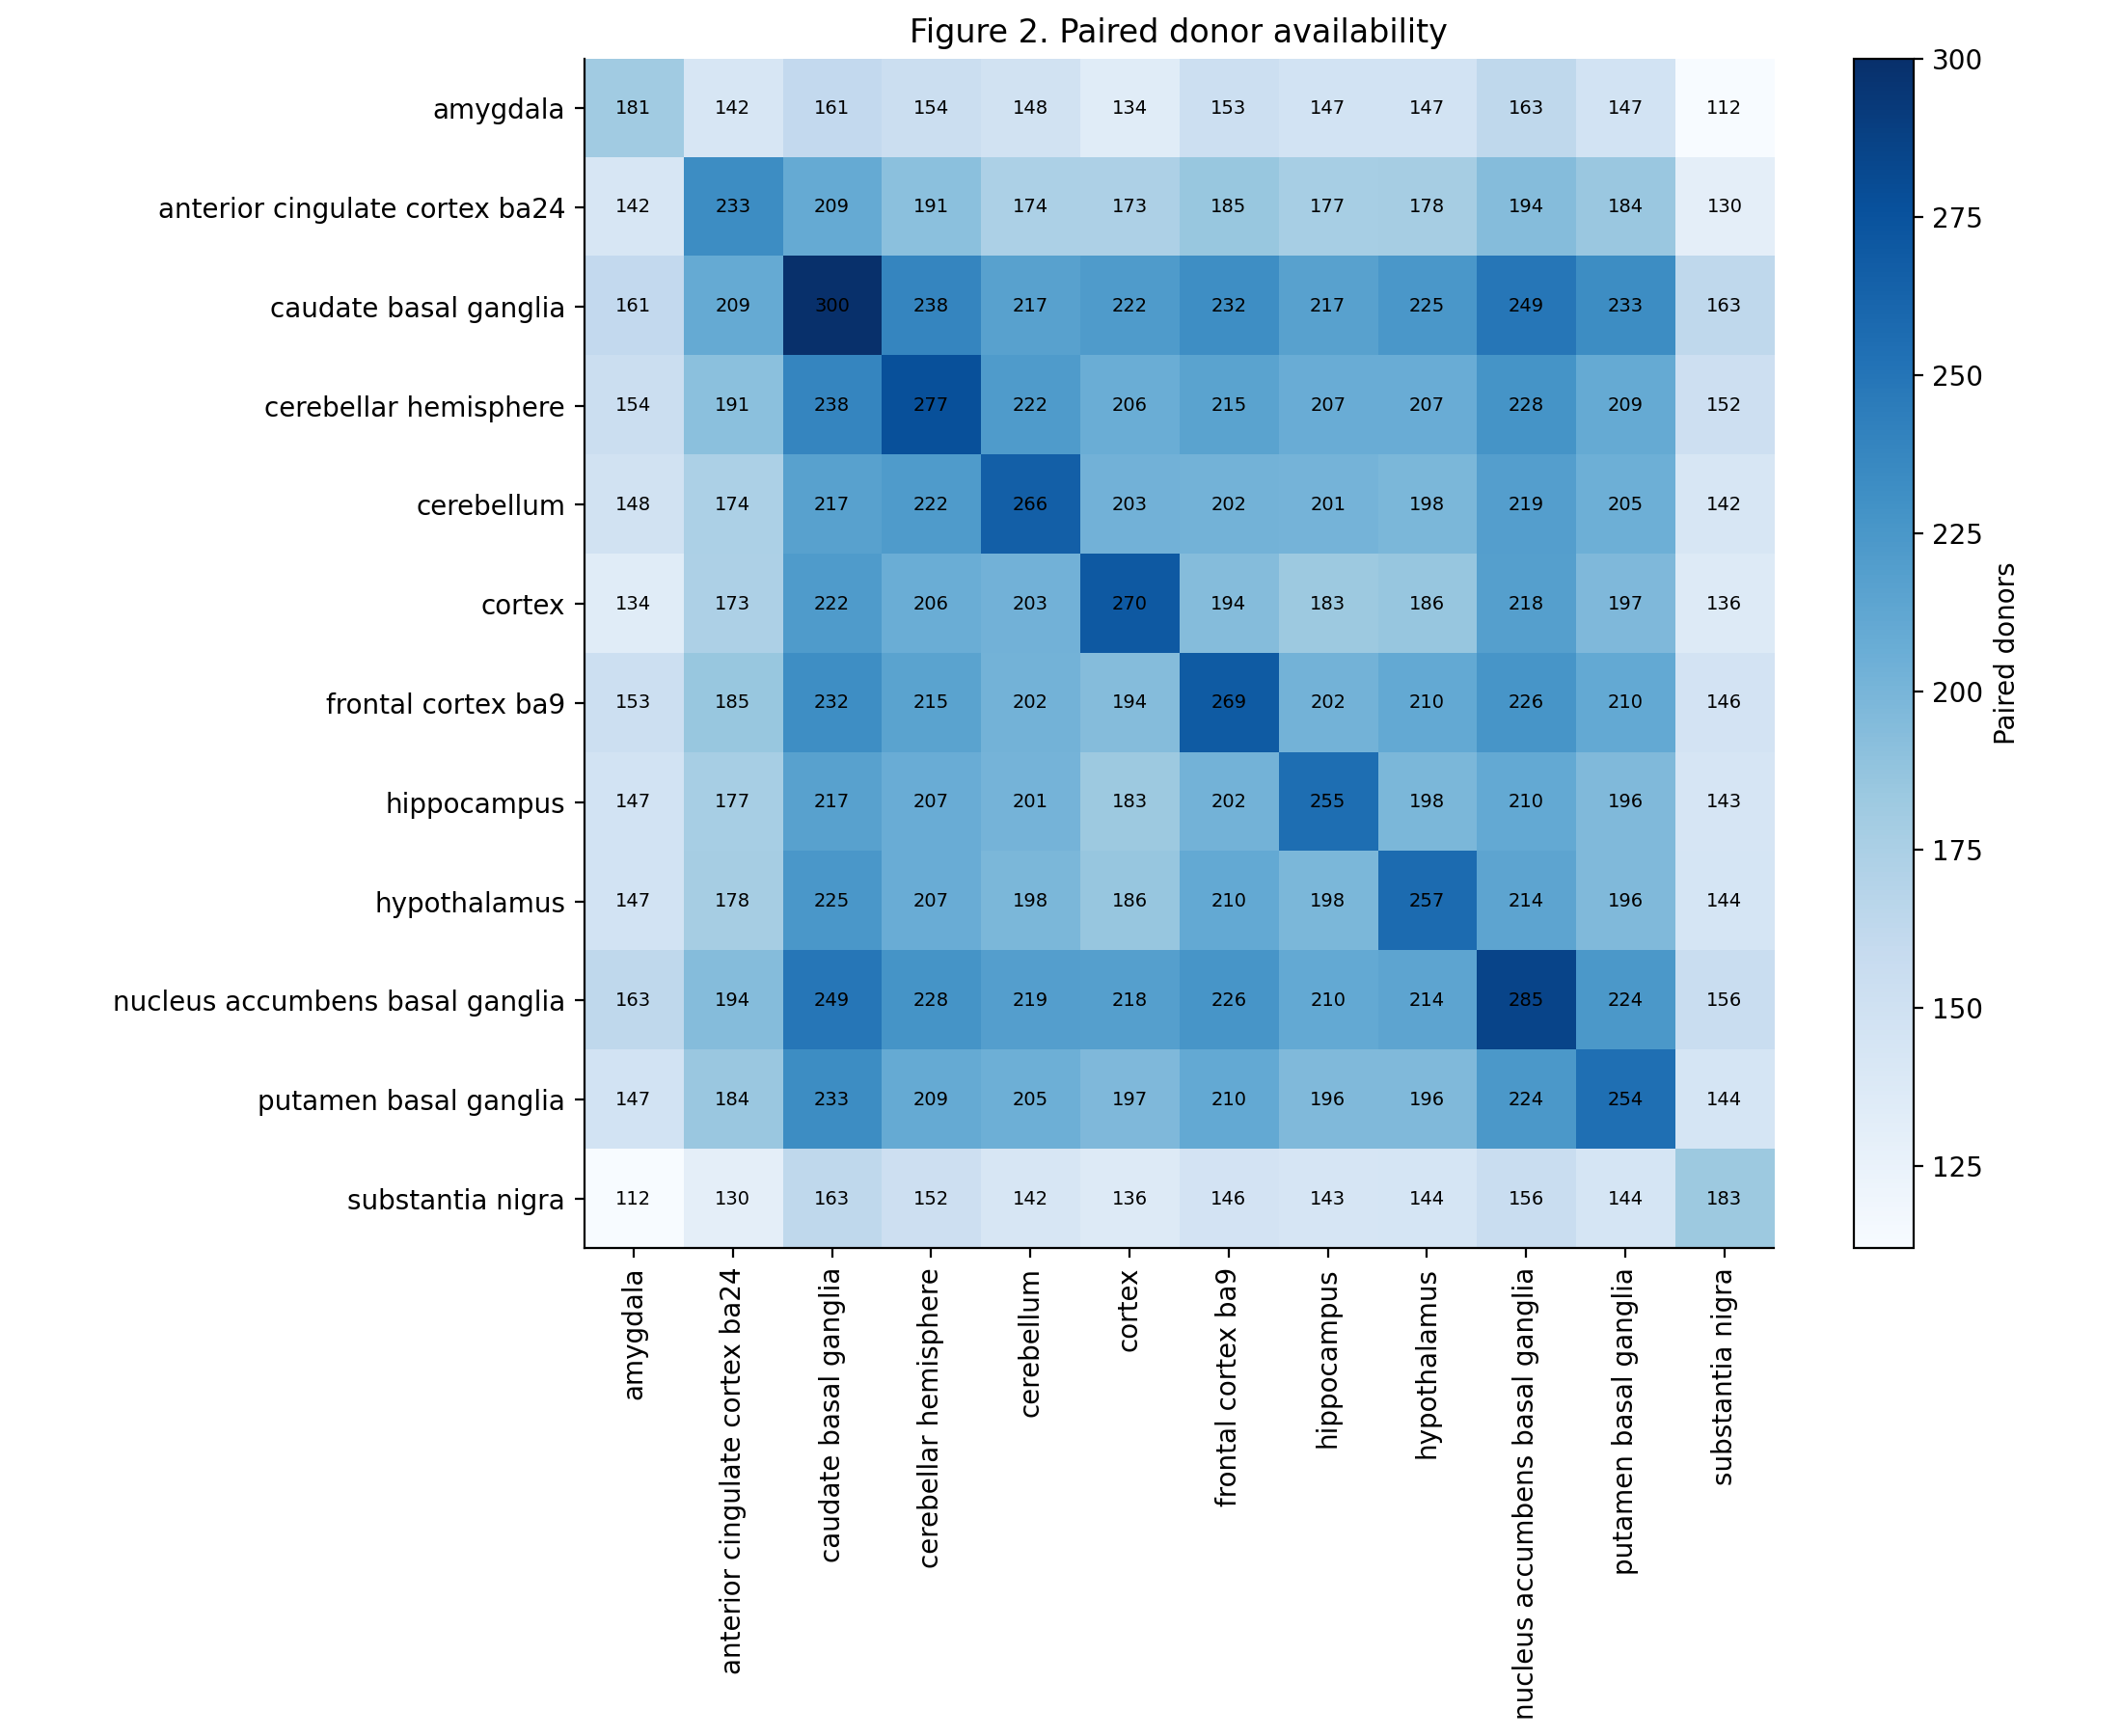

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
s = summary.sort_values('donors')
ax.barh(s.region.str.replace('_', ' '), s.donors, color='#357da8')
ax.set(xlabel='Unique donors', title='Figure 1. Available donors by region')
fig.tight_layout(); fig.savefig(OUT / 'figure_1_region_counts.png', dpi=200); plt.show()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(overlap, cmap='Blues')
labels = [r.replace('_', ' ') for r in active]
ax.set_xticks(range(len(active)), labels, rotation=90)
ax.set_yticks(range(len(active)), labels)
for i in range(len(active)):
    for j in range(len(active)):
        ax.text(j, i, str(overlap.iloc[i,j]), ha='center', va='center', fontsize=7)
ax.set_title('Figure 2. Paired donor availability')
fig.colorbar(im, ax=ax, label='Paired donors')
fig.tight_layout(); fig.savefig(OUT / 'figure_2_donor_overlap.png', dpi=200); plt.show()

## 5. Prediction and evaluation
For each direction, hold out 20% of paired donors. From the remaining donors, reserve an inner validation set to select alpha. Source and target genes are selected separately using only the inner training set: expression equivalent to CPM > 1 in at least 20% of donors, then highest variance. This fixed gene set is reused when fitting on all development donors. Scaling is fitted independently at each training stage.

The baseline predicts each target gene's development-set mean. The primary **prediction skill** is `1 − model MSE / baseline MSE`, where errors are averaged over donors and selected target genes. Zero matches the baseline, positive improves it, and negative is worse. This is baseline-relative skill, not conventional test R². Gene-wise test R² is exported separately. Bootstrap intervals resample held-out donors using fixed predictions; they quantify test-cohort uncertainty conditional on the fitted model, not training uncertainty. Do not treat genes as independent patients.

Different pairs use different selected targets and donors. The all-pair heatmap is exploratory; confirm rankings with repeated donor splits and common-target/common-cohort sensitivity analyses before interpreting pair differences biologically.

In [ ]:
def choose_genes(frame, n):
    expressed = (frame > 1).mean(axis=0) >= 0.2
    variance = frame.var(axis=0)
    ranked = variance[expressed & (variance > 1e-8)].sort_values(ascending=False)
    if len(ranked) < 10:
        raise ValueError('Too few expressed variable genes')
    return ranked.index[:n]

def analyze_pair(source, target):
    ids = regions[source].index.intersection(regions[target].index).sort_values()
    if len(ids) < MIN_PAIRED_DONORS:
        return None
    dev, test = train_test_split(np.arange(len(ids)), test_size=0.2, random_state=SEED)
    inner, val = train_test_split(dev, test_size=0.25, random_state=SEED)
    Xframe, Yframe = regions[source].loc[ids], regions[target].loc[ids]
    xgenes = choose_genes(Xframe.iloc[inner], N_SOURCE_GENES)
    ygenes = choose_genes(Yframe.iloc[inner], N_TARGET_GENES)
    X = Xframe[xgenes].to_numpy(dtype='float64')
    Y = Yframe[ygenes].to_numpy(dtype='float64')
    scaler = StandardScaler().fit(X[inner])
    Xi, Xv = scaler.transform(X[inner]), scaler.transform(X[val])
    validation = []
    for alpha in ALPHAS:
        fit = Ridge(alpha=alpha, solver='cholesky').fit(Xi, Y[inner])
        validation.append(np.mean((Y[val] - fit.predict(Xv))**2))
    best = ALPHAS[int(np.argmin(validation))]
    scaler = StandardScaler().fit(X[dev])
    model = Ridge(alpha=best, solver='cholesky').fit(scaler.transform(X[dev]), Y[dev])
    truth = Y[test]
    pred = model.predict(scaler.transform(X[test]))
    baseline = np.broadcast_to(Y[dev].mean(axis=0), truth.shape)
    model_loss = ((truth-pred)**2).mean(axis=1)
    base_loss = ((truth-baseline)**2).mean(axis=1)
    skill = 1-model_loss.mean()/base_loss.mean()
    rng = np.random.default_rng(SEED)
    sampled = rng.integers(0, len(test), size=(N_BOOTSTRAPS, len(test)))
    bs = 1-model_loss[sampled].mean(axis=1)/base_loss[sampled].mean(axis=1)
    lo, hi = np.quantile(bs, [0.025, 0.975])
    sse = ((truth-pred)**2).sum(axis=0)
    sst = ((truth-truth.mean(axis=0))**2).sum(axis=0)
    r2 = np.divide(sse, sst, out=np.full_like(sse, np.nan), where=sst>1e-12)
    gene_table = pd.DataFrame({'gene_id':ygenes, 'symbol':symbols[target].reindex(ygenes).values,
                               'test_r2':1-r2, 'model_mse':((truth-pred)**2).mean(axis=0),
                               'baseline_mse':((truth-baseline)**2).mean(axis=0)})
    prefix = source+'__to__'+target
    gene_table.to_csv(OUT / (prefix+'_genes.csv'), index=False)
    # Keep donor-level files local; avoid sharing IDs in public repositories.
    pd.DataFrame({'donor_id':ids[test], 'model_mse':model_loss, 'baseline_mse':base_loss}).to_csv(OUT / (prefix+'_test_errors_PRIVATE.csv'), index=False)
    pd.DataFrame({'donor_id':ids, 'split':['test' if i in test else 'development' for i in range(len(ids))]}).to_csv(OUT / (prefix+'_splits_PRIVATE.csv'), index=False)
    row = dict(source=source,target=target,n_paired=len(ids),n_development=len(dev),n_test=len(test),
               n_source_genes=len(xgenes),n_target_genes=len(ygenes),alpha=best,
               model_mse=model_loss.mean(),baseline_mse=base_loss.mean(),
               skill=skill,ci_low=lo,ci_high=hi)
    return row, dict(truth=truth,pred=pred,baseline=baseline,genes=gene_table)

pairs = list(itertools.permutations(active, 2)) if RUN_ALL_PAIRS else [(SOURCE,TARGET)]
results, skipped, example = [], [], None
for source,target in pairs:
    if source not in active or target not in active:
        raise ValueError('Selected region unavailable or excluded')
    output = analyze_pair(source,target)
    if output is None:
        skipped.append({'source':source,'target':target,'reason':'too few paired donors'})
        continue
    row, detail = output
    results.append(row)
    if example is None:
        example = (row,detail)
    print(source,'→',target, 'skill:',round(row['skill'],3))
if not results:
    raise ValueError('No eligible pairs. Inspect overlap and minimum donor threshold.')
results = pd.DataFrame(results)
results.to_csv(OUT / 'table_2_prediction_results.csv',index=False)
pd.DataFrame(skipped).to_csv(OUT / 'skipped_pairs.csv', index=False)
display(results)

## 6. Result graphs
**Figure 3.** Prediction skill with conditional 95% donor-bootstrap intervals. Zero indicates the mean-expression baseline. An interval crossing zero does not show clear improvement for this held-out cohort.

**Figure 4.** Predicted versus observed expression for the example target gene with greatest variance in the development donors (not selected for best test performance). Each point is one test donor. The dashed line is perfect prediction.

**Figure 5 (all-pair mode).** Directional prediction skill. Rows are sources, columns are targets; missing pairs remain blank. Pairwise rankings require the sensitivity analyses described above.

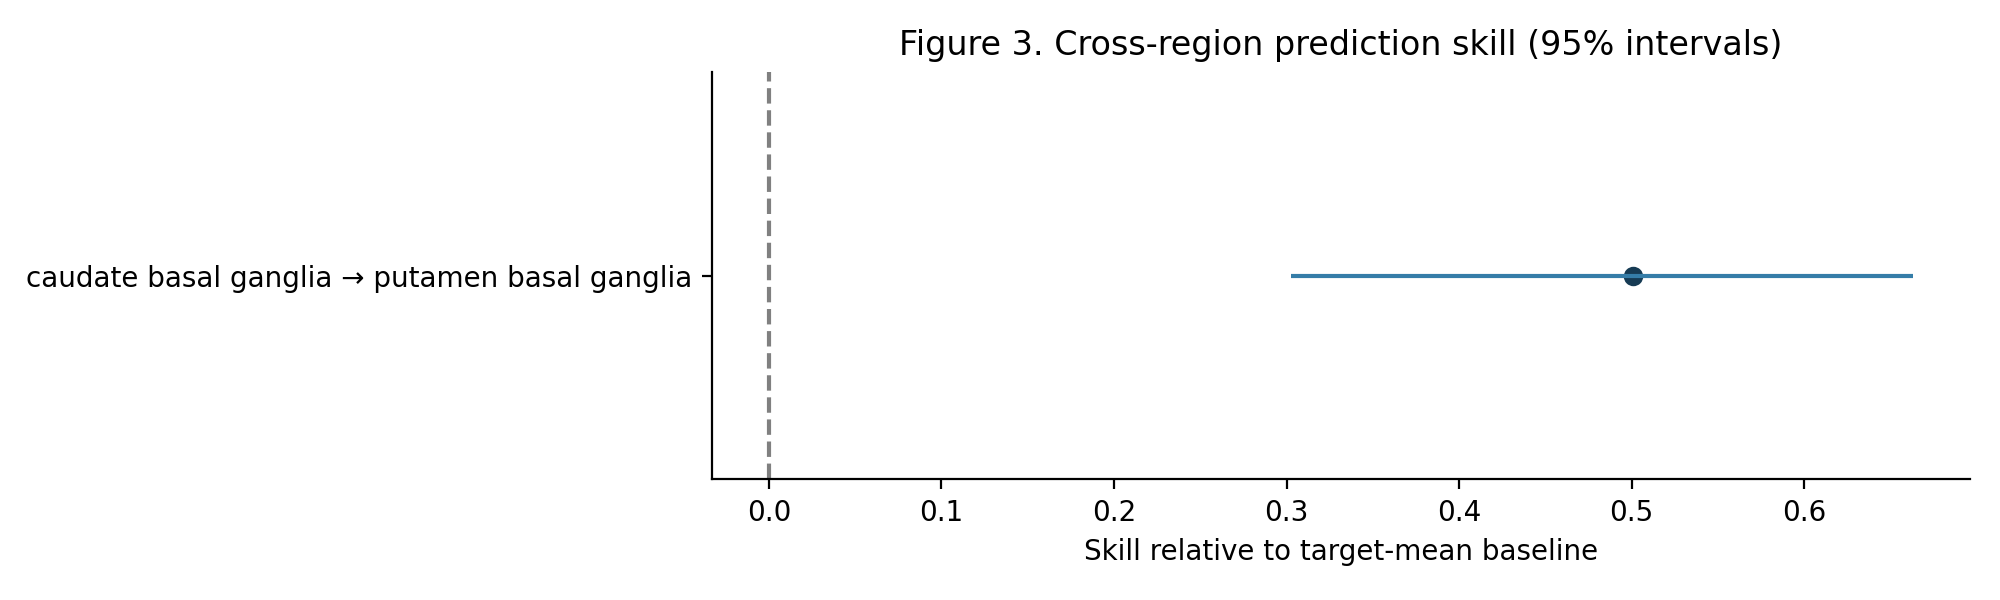

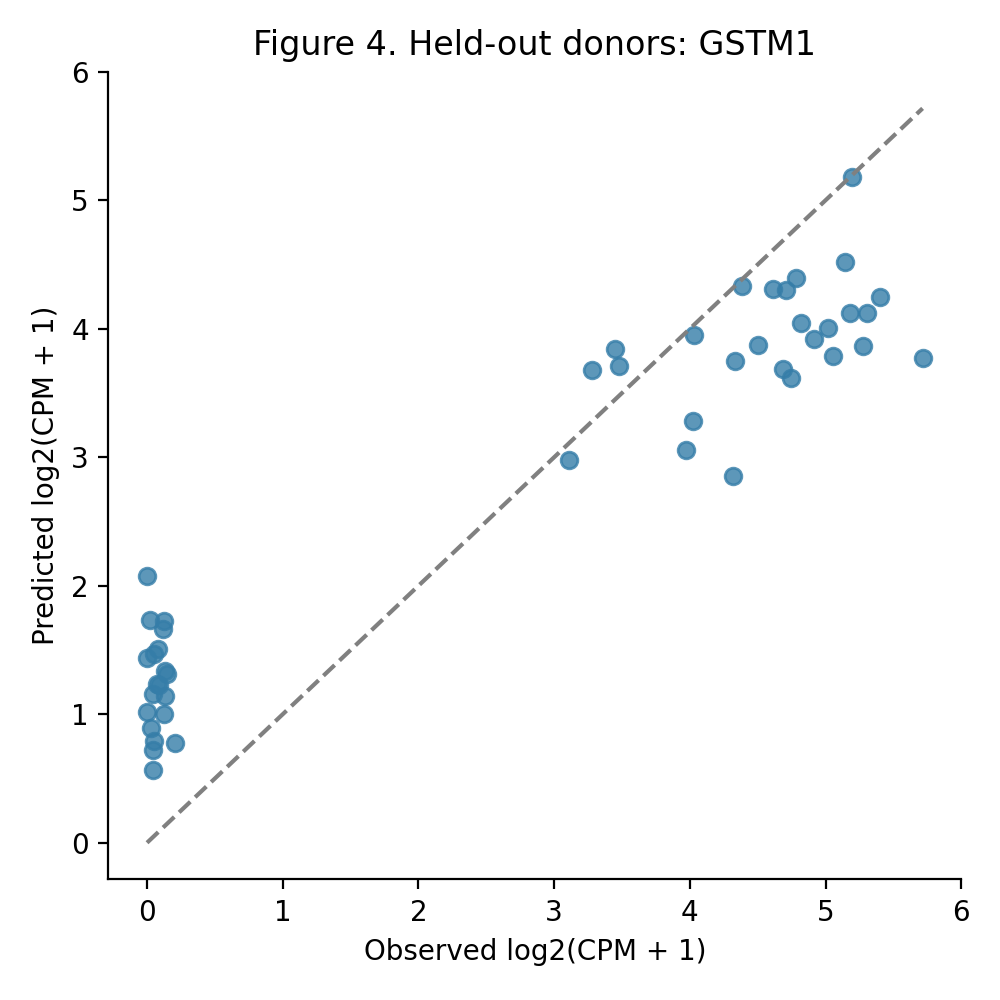

In [ ]:
r = results.sort_values('skill')
fig, ax = plt.subplots(figsize=(10,max(3,0.3*len(r))))
y = np.arange(len(r))
ax.hlines(y,r.ci_low,r.ci_high,color='#357da8')
ax.scatter(r.skill,y,color='#163b54')
ax.set_yticks(y, [a.replace('_',' ')+' → '+b.replace('_',' ') for a,b in zip(r.source,r.target)])
ax.axvline(0,color='gray',linestyle='--')
ax.set(xlabel='Skill relative to target-mean baseline',title='Figure 3. Cross-region prediction skill (95% intervals)')
fig.tight_layout(); fig.savefig(OUT / 'figure_3_prediction_skill.png',dpi=200); plt.show()
row, detail = example
# Target genes are ordered by development-inner-training variance.
j = 0
truth, pred = detail['truth'][:,j], detail['pred'][:,j]
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(truth,pred,alpha=0.8,color='#357da8')
limits = [min(truth.min(),pred.min()),max(truth.max(),pred.max())]
ax.plot(limits,limits,'--',color='gray')
name = detail['genes'].iloc[j]['symbol']
ax.set(xlabel='Observed log2(CPM + 1)',ylabel='Predicted log2(CPM + 1)',title=f'Figure 4. Held-out donors: {name}')
fig.tight_layout(); fig.savefig(OUT / 'figure_4_example_gene.png',dpi=200); plt.show()
if RUN_ALL_PAIRS:
    heat = results.pivot(index='source',columns='target',values='skill').reindex(index=active,columns=active)
    fig, ax = plt.subplots(figsize=(11,9))
    bound = max(1,float(np.nanmax(np.abs(heat.to_numpy()))))
    im = ax.imshow(np.ma.masked_invalid(heat.to_numpy()),cmap='RdBu',vmin=-bound,vmax=bound)
    ax.set_xticks(range(len(active)),labels,rotation=90)
    ax.set_yticks(range(len(active)),labels)
    ax.set(xlabel='Target',ylabel='Source',title='Figure 5. Directional prediction skill')
    fig.colorbar(im,ax=ax,label='Prediction skill')
    fig.tight_layout(); fig.savefig(OUT / 'figure_5_transferability_heatmap.png',dpi=200); plt.show()

## 7. Interpretation and project reporting
Use `table_1_dataset_summary.csv` and Figures 1–2 for the dataset description. Use `table_2_prediction_results.csv` and Figure 3 for the primary result and baseline comparison. Gene-level CSVs support exploratory error analysis.

Report actual results, including negative skill. High performance supports predictable cross-region variation in this design; it does not establish a causal molecular connection. Age, sex, tissue quality, batch and cell mixture may explain part of the prediction. GTEx tissue donors are not an HD/PD case-control cohort. No disease data were attached, so disease validation is not included.

Before the final paper: add verified GTEx V11 provenance/access date and data-use terms; obtain permitted sample/donor covariates; examine normalization sensitivity; repeat donor splits; compare pairs on common genes and, where feasible, the same donors; distinguish exploratory gene rankings from confirmed biological pathways. Follow GTEx privacy and sharing rules. Do not publish donor-level outputs or original expression matrices without verifying terms.

For BMEN 600: number and caption figures, explain the baseline and uncertainty, acknowledge model and cohort limitations, include this notebook in your GitHub repository, record the submitted commit, and add author contributions and an AI-use statement. Suggested AI statement to adapt truthfully: “ChatGPT assisted with notebook construction and method explanations. Team members verified references, reviewed donor splitting and preprocessing, ran the analysis, and checked outputs.”

In [ ]:
metadata = {'question':'Cross-region prediction in unseen GTEx donors', 'seed':SEED,
            'run_all_pairs':RUN_ALL_PAIRS,'include_spinal_cord':INCLUDE_SPINAL_CORD,
            'normalization':'log2(CPM+1); total gene counts per sample',
            'source_genes':N_SOURCE_GENES,'target_genes':N_TARGET_GENES,
            'alphas':ALPHAS,'bootstraps':N_BOOTSTRAPS,
            'python':platform.python_version(),'numpy':np.__version__,
            'pandas':pd.__version__,'sklearn':sklearn.__version__,
            'input_files':records}
(OUT/'analysis_metadata.json').write_text(json.dumps(metadata,indent=2))
# Public export omits files labelled PRIVATE. Keep full local results for verification.
PUBLIC = Path('/content/gtex_public_results')
PUBLIC.mkdir(exist_ok=True)
for old in PUBLIC.iterdir():
    if old.is_file(): old.unlink()
for p in OUT.iterdir():
    if p.is_file() and 'PRIVATE' not in p.name:
        shutil.copy2(p,PUBLIC/p.name)
archive = shutil.make_archive('/content/gtex_results_public','zip',PUBLIC)
from google.colab import files
files.download(archive)

## 8. References (IEEE-style)
[1] M. J. Hawrylycz et al., “An anatomically comprehensive atlas of the adult human brain transcriptome,” *Nature*, vol. 489, pp. 391–399, 2012. doi: [10.1038/nature11405](https://doi.org/10.1038/nature11405).

[2] M. Hawrylycz et al., “Canonical genetic signatures of the adult human brain,” *Nature Neuroscience*, vol. 18, pp. 1832–1844, 2015. doi: [10.1038/nn.4171](https://doi.org/10.1038/nn.4171).

[3] GTEx Consortium, “The GTEx Consortium atlas of genetic regulatory effects across human tissues,” *Science*, vol. 369, pp. 1318–1330, 2020. doi: [10.1126/science.aaz1776](https://doi.org/10.1126/science.aaz1776). Background publication for GTEx; it describes V8, **not** the supplied V11 release. Add the verified V11 release citation/provenance separately.

[4] M. D. Robinson and A. Oshlack, “A scaling normalization method for differential expression analysis of RNA-seq data,” *Genome Biology*, vol. 11, R25, 2010. doi: [10.1186/gb-2010-11-3-r25](https://doi.org/10.1186/gb-2010-11-3-r25). Supports discussion of compositional bias; TMM is not implemented here.

[5] A. E. Hoerl and R. W. Kennard, “Ridge regression: Biased estimation for nonorthogonal problems,” *Technometrics*, vol. 12, no. 1, pp. 55–67, 1970. doi: [10.1080/00401706.1970.10488634](https://doi.org/10.1080/00401706.1970.10488634).

[6] S. Varma and R. Simon, “Bias in error estimation when using cross-validation for model selection,” *BMC Bioinformatics*, vol. 7, art. 91, 2006. doi: [10.1186/1471-2105-7-91](https://doi.org/10.1186/1471-2105-7-91). Supports separating tuning from evaluation; this notebook uses separate validation/test splits rather than nested cross-validation.

Software: [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html), [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).